![](https://europe-west1-atp-views-tracker.cloudfunctions.net/working-analytics?notebook=tutorials--fine-tunning-agents--fine-tuning-agents-guide)

# Enhancing AI Agents Through Fine-Tuning Guide
## Overview
This tutorial demonstrates how to leverage supervised fine-tuning (SFT) to create more capable and efficient AI agents. While we'll use a banking example for demonstration, the techniques and principles covered here apply to any scenario where you need to enhance an AI agent's capabilities through fine-tuning.

## What is Fine-Tuning?

Fine-tuning is the process of taking a pre-trained AI model—one that has already learned general language patterns from vast amounts of data—and further training it on a smaller, specialized dataset. 

This additional training helps the model adapt to specific domains, tasks, or communication styles, making it more effective and reliable for targeted applications. Fine-tuning allows you to customize the model’s behavior, vocabulary, and output format to better suit your unique needs.

## Why Fine-Tune AI Agents?
Fine-tuning offers several powerful advantages for AI agent development:

1. **Domain Expertise**: 
   - Internalizes domain-specific regulations and compliance requirements

   - Reduces hallucinations in specialized contexts

2. **Consistent Style & Tone**:
   - Learns to maintain your brand voice consistently

   - Provides uniform responses across all interactions

3. **Structured Outputs**:
   - Reliably generates specific formats (JSON, SQL, Markdown)

4. **Reduced Prompt Engineering**:
   - Eliminates need for lengthy system prompts

   - Significantly reduces token usage and costs

5. **Enhanced Efficiency**:
   - Smaller tuned models can replace larger base models

   - Faster response times for specialized tasks


### Who Should Consider Fine-Tuning?
- Teams building specialized AI agents for specific domains

- Applications where response speed and cost matter

- Systems handling complex domain-specific tasks

## Method Overview
1. **Data Preparation**: Creating high-quality training datasets that capture desired behaviors

2. **Supervised Fine-Tuning**: Adapting foundation models to specific requirements

3. **Integration**: Building efficient agent workflows with fine-tuned models

4. **Evaluation**: Measuring performance improvements across key metrics


This approach provides a robust framework for enhancing AI agents through fine-tuning, enabling them to perform specialized tasks more effectively while maintaining efficiency and reliability.

## Conclusion
This tutorial shows how to leverage fine-tuning to create more capable AI agents. Whether you need domain expertise, consistent formatting, or improved efficiency, fine-tuning can help your agents perform better while reducing costs and complexity. The techniques demonstrated here can be applied across any industry or use case where specialized agent behavior is desired.

Written by [Zohar Mosseri](https://europe-west1-atp-views-tracker.cloudfunctions.net/working-analytics?notebook=tutorials--fine-tunning-agents--fine-tuning-agents-guide&click=linkedin-zohar-mosseri&target=https%3A%2F%2Fwww.linkedin.com%2Fin%2Fzohar-mosseri%2F&text=Zohar%20Mosseri)

> **Note (31 Oct 2026): this tutorial now fine-tunes an open model on your own machine.** It originally used OpenAI's hosted fine-tuning API, but per [OpenAI's fine-tuning guide](https://developers.openai.com/api/docs/guides/supervised-fine-tuning) that platform is closed to new users, existing customers can create training jobs only until January 6, 2027, and its supported base models shut down on January 14, 2027. The notebook now trains a LoRA adapter on a small open model with Hugging Face TRL and PEFT: no API key, no paid service, and it trains on a laptop CPU in minutes (a GPU, such as a free Colab one, makes it faster). The training files are the same chat-format JSONL (`{"messages": [...]}`) that hosted supervised fine-tuning services accept, so if you use a provider that still offers hosted SFT you can upload these exact files there and keep the evaluation steps unchanged.

📖 **For more background on fine-tuning AI models and their applications, check out our detailed blog post:** [Fine-tuning AI models](https://europe-west1-atp-views-tracker.cloudfunctions.net/working-analytics?notebook=tutorials--fine-tunning-agents--fine-tuning-agents-guide&click=substack-diamantai&target=https%3A%2F%2Fdiamantai.substack.com%2Fp%2Ffine-tuning-ai-models-how-they-evolve&text=Fine-tuning%20AI%20models)

*DiamantAI is a top 0.1% newsletter for AI with over 25,000 subscribers, focusing on AI techniques, breakthroughs, and tutorials.*

---


## Example Use Case: Banking Assistant
To demonstrate these concepts, we'll create a banking customer support assistant. This example will show how to:
- Structure training data for domain-specific knowledge
- Fine-tune a model for specialized tasks
- Integrate the fine-tuned model into a practical application

## 1. Setup and Imports

Install and import the necessary libraries. Everything in this notebook runs locally: no API keys and no paid services. A laptop CPU is enough (Python 3.11 or newer); if a CUDA GPU or Apple Silicon (MPS) is available, it is used automatically.

In [1]:
# Tested with Python 3.11: torch 2.15.0, transformers 5.22.1, trl 1.17.1, peft 0.21.2, datasets 5.1.0,
# accelerate 1.15.0, langgraph 1.2.19, pandas 3.1.0, matplotlib 3.11.2.
# torch, pandas and matplotlib are left unpinned so an existing install (e.g. on Colab) is reused.
%pip install -q "torch>=2.6" transformers==5.22.1 trl==1.17.1 peft==0.21.2 datasets==5.1.0 accelerate==1.15.0 langgraph==1.2.19 pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random, time, warnings

import torch
import transformers, trl, peft, datasets
from huggingface_hub.utils import disable_progress_bars

# The one place to change the base model. Any small chat model with a chat template works,
# e.g. "HuggingFaceTB/SmolLM2-360M-Instruct" or "Qwen/Qwen2.5-0.5B-Instruct" (slower to train, better with new phrasings).
BASE_MODEL_ID = "HuggingFaceTB/SmolLM2-135M-Instruct"
SEED = 42

# Use the fastest available device: CUDA GPU, then Apple Silicon (MPS), then CPU.
# Set DEVICE = "cpu" to force CPU training.
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

random.seed(SEED)
transformers.set_seed(SEED)

# Keep the output readable: no progress bars or library chatter
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
datasets.disable_progress_bars()
disable_progress_bars()
warnings.filterwarnings("ignore")

print(f"torch {torch.__version__} | transformers {transformers.__version__} | trl {trl.__version__} | peft {peft.__version__}")
print(f"Base model: {BASE_MODEL_ID} | device: {DEVICE}")

torch 2.15.0 | transformers 5.22.1 | trl 1.17.1 | peft 0.21.2
Base model: HuggingFaceTB/SmolLM2-135M-Instruct | device: mps


## 2. Prepare Training & Validation Files for Fine-tuning

Supervised fine-tuning tools, including TRL's `SFTTrainer` used below and the hosted fine-tuning services, expect **UTF-8 encoded JSONL** files, with one JSON object per line.
Each example follows the chat format with system, user, and assistant messages.

### Understanding the Training Data Format
The quality of your fine-tuned model depends heavily on your training data. Here's what you need to know:

1. **File Format**: JSONL (JSON Lines) with UTF-8 encoding

2. **Message Structure**: Each example must contain a sequence of messages with roles and content

3. **Required Fields**: Each message needs `role` and `content` fields

4. **Valid Roles**: `system`, `user`, and `assistant`

### Example Format
```jsonl
{
  "messages": [
    {"role": "system", "content": "You are a helpful domain expert assistant."},
    {"role": "user", "content": "What is the policy on this matter?"},
    {"role": "assistant", "content": "According to our policies..."}
  ]
}
```

### Creating Training Data: A Banking Example
To demonstrate these principles, let's create a training dataset using a banking knowledge base. This example can be adapted for any domain-specific knowledge:

In [3]:
import json
import random
import pathlib
import pandas as pd


# Create directory for our fine-tuning data
DATA_DIR = pathlib.Path("bank_finetune_data")
DATA_DIR.mkdir(exist_ok=True)

# --- General Approach to Creating Training Data ---
# 1. Use your domain knowledge base (docs, FAQs, policies, etc.)
# 2. Structure content into clear topics
# 3. Create diverse, well-phrased Q&A pairs

# Example using banking domain
kb_docs = [
    {
        "title": "Account Types",
        "content": {
            "checking": "We offer three types of checking accounts: Basic (no minimum balance), Premium ($2,500 minimum, no fees), and Student (no fees with valid student ID).",
            "savings": "Our savings accounts include Regular (0.5% APY), High-Yield (1.5% APY with $10,000 minimum), and Goal-Based savings with customizable targets.",
            "business": "Business accounts feature unlimited transactions, merchant services integration, and dedicated support. Available in Standard and Premium tiers."
        }
    },
    # Additional examples below - uncomment to create a more comprehensive training set
    # For tutorial purposes, we'll start with a single example to demonstrate the process
    # {
    #     "title": "Security Protocols",
    #     "content": {
    #         "authentication": "We use multi-factor authentication, biometric verification, and device recognition. Login attempts are limited to 3 tries before temporary lockout.",
    #         "fraud_prevention": "Real-time transaction monitoring, instant fraud alerts, and zero liability protection for unauthorized charges.",
    #         "data_protection": "End-to-end encryption for all transactions, secure socket layer (SSL) protection, and regular security audits."
    #     }
    # },
    # {
    #     "title": "Digital Banking",
    #     "content": {
    #         "mobile_features": "Mobile check deposit, peer-to-peer payments, bill pay, and account aggregation across institutions.",
    #         "online_services": "Budget tracking, spending analysis, electronic statements, and customizable alerts.",
    #         "technical_requirements": "Compatible with iOS 13+ and Android 8+. Requires secure internet connection and updated browser versions."
    #     }
    # }
]

def generate_diverse_examples(kb_doc):
    """
    Generate multiple training examples with diverse phrasings and scenarios.
    Following best practices for high-quality training data.
    """
    examples = []
    content = kb_doc["content"]
    
    # Generate examples for each subtopic
    for subtopic, details in content.items():
        # Multiple question variations
        questions = [
            f"Can you explain {subtopic}?",
            f"What should I know about {subtopic}?",
            f"Tell me about your {subtopic}",
            f"How does {subtopic} work?",
            f"I need information regarding {subtopic}",
            f"What are the details of {subtopic}?"
        ]
        
        # Multiple response variations with consistent style
        responses = [
            f"Here's what you need to know about {subtopic}: {details}",
            f"Regarding {subtopic}: {details} Let me know if you need any clarification.",
            f"I'll explain {subtopic}. {details} Is there anything specific you'd like to know more about?",
            f"{details} This information about {subtopic} is current as of today. Please check our website for any updates."
        ]
        
        # Generate combinations with system message variations
        system_messages = [
            "You are a knowledgeable banking assistant focused on providing accurate, compliant information.",
            "You are a helpful financial services expert committed to clear, precise communication.",
            "You are a banking specialist dedicated to providing detailed, accurate responses."
        ]
        
        # Create multiple examples for each subtopic
        for system_msg in system_messages:
            for question in questions:
                for response in responses:
                    examples.append({
                        "messages": [
                            {"role": "system", "content": system_msg},
                            {"role": "user", "content": question},
                            {"role": "assistant", "content": response}
                        ]
                    })
    
    return examples

# Generate comprehensive training dataset
examples = []
for doc in kb_docs:
    examples.extend(generate_diverse_examples(doc))

# Shuffle examples to ensure good distribution
random.shuffle(examples)

print(f"Generated {len(examples)} diverse training examples")


Generated 216 diverse training examples


### Data Quality Best Practices for Fine-Tuning

The success of your fine-tuned model depends on well-structured training data. Key principles:

1. **Data Requirements**
   - At least 10 examples per behavior
   - Balance types and reserve 10–20% for validation

2. **Quality Guidelines**
   - Clear intent and response in each example
   - Vary phrasing, keep formatting and style consistent
   - Reflect real-world usage

3. **Common Pitfalls**
   - Avoid sensitive info, inconsistent styles, duplicates, and overfitting

Remember: Quality over quantity: a small set of high-quality examples outperforms a large set of poor ones.

### Split into training and validation sets

A crucial step in fine-tuning is dividing your dataset into training and validation sets. The training set teaches the model, while the validation set helps measure its performance on unseen data. We'll use a 80/20 split - a common ratio that provides enough validation data while maximizing training examples.

In [4]:
# Randomly shuffle examples to ensure even distribution between sets
random.shuffle(examples)

# Calculate split point for 80% training, 20% validation
split_index = int(0.8 * len(examples))

# Split examples into training and validation sets
train_examples, validation_examples = examples[:split_index], examples[split_index:]

# Save to JSONL files
train_file = DATA_DIR / "train.jsonl"
validation_file = DATA_DIR / "validation.jsonl"

with open(train_file, "w", encoding="utf-8") as f:
    for example in train_examples:
        f.write(json.dumps(example, ensure_ascii=False) + "\n")

with open(validation_file, "w", encoding="utf-8") as f:
    for example in validation_examples:
        f.write(json.dumps(example, ensure_ascii=False) + "\n")

print(f"✍️ Created {len(train_examples)} training examples and {len(validation_examples)} validation examples")

# Create a DataFrame for easy visualization of example structure
df = pd.DataFrame([
    {
        "system": ex["messages"][0]["content"],
        "user": ex["messages"][1]["content"],
        "assistant": ex["messages"][2]["content"]
    }
    for ex in train_examples[:3]
])
# Display first 3 examples showing system, user, and assistant messages
df

✍️ Created 172 training examples and 44 validation examples


,system,user,assistant
0,You are a knowledgeable banking assistant focu...,Can you explain savings?,Our savings accounts include Regular (0.5% APY...
1,You are a knowledgeable banking assistant focu...,What should I know about savings?,Here's what you need to know about savings: Ou...
2,You are a helpful financial services expert co...,Tell me about your business,Business accounts feature unlimited transactio...


### Validating the JSONL format

Before training, let's validate our files so formatting errors surface now rather than halfway through a training run:

In [5]:
def validate_jsonl(file_path):
    """Validate that the file is proper JSONL format for fine-tuning."""
    with open(file_path, 'r', encoding='utf-8') as f:
        line_count = 0
        for line in f:
            line_count += 1
            try:
                data = json.loads(line)
                # Check if it has the messages field
                if 'messages' not in data:
                    return False, f"Line {line_count} missing 'messages' field"
                # Check message format
                for msg in data['messages']:
                    if 'role' not in msg or 'content' not in msg:
                        return False, f"Line {line_count} has message missing 'role' or 'content'"
                    if msg['role'] not in ['system', 'user', 'assistant']:
                        return False, f"Line {line_count} has invalid role: {msg['role']}"
            except json.JSONDecodeError:
                return False, f"Line {line_count} is not valid JSON"
    return True, f"Validated {line_count} examples"

# Validate our files
train_valid, train_msg = validate_jsonl(train_file)
val_valid, val_msg = validate_jsonl(validation_file)

print(f"Training file: {'✅' if train_valid else '❌'} {train_msg}")
print(f"Validation file: {'✅' if val_valid else '❌'} {val_msg}")

Training file: ✅ Validated 172 examples
Validation file: ✅ Validated 44 examples


### How much does this dataset actually teach?

Over two hundred examples sounds like a lot, but count what is inside them: three facts (one paragraph each for checking, savings and business), six question templates, four answer templates and three system messages. A random split of such data also means the validation set mostly repeats questions and answers the model trains on. Let's measure it rather than assume it:

In [6]:
train_questions = {ex["messages"][1]["content"] for ex in train_examples}
train_answers = {ex["messages"][2]["content"] for ex in train_examples}

print(f"Distinct questions in training: {len(train_questions)}, distinct answers: {len(train_answers)}")
q_overlap = sum(ex["messages"][1]["content"] in train_questions for ex in validation_examples)
a_overlap = sum(ex["messages"][2]["content"] in train_answers for ex in validation_examples)
print(f"Validation examples whose question also appears in training: {q_overlap}/{len(validation_examples)}")
print(f"Validation examples whose answer also appears in training:   {a_overlap}/{len(validation_examples)}")

Distinct questions in training: 18, distinct answers: 12
Validation examples whose question also appears in training: 44/44
Validation examples whose answer also appears in training:   44/44


So the validation loss can tell us whether the model learned these templates, not whether it can answer a question phrased the way a real customer would phrase it. To measure that, we'll write a small held-out test set with new phrasings in section 4 and use it both during training and in the final comparison.

## 3. Load the Base Model

The base model is set by `BASE_MODEL_ID` at the top of the notebook. The default, `HuggingFaceTB/SmolLM2-135M-Instruct`, is a 135M-parameter instruct model: ungated (no access request or token needed), about 270 MB to download, and small enough to fine-tune on a laptop CPU in minutes. The trade-off is quality. It is far weaker than the hosted models this tutorial originally used, which makes it a good place to see both what fine-tuning does and where it stops.

The tokenizer's chat template turns each `messages` list into the exact text the model trains on:

In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID, dtype=torch.float32).to(DEVICE)
print(f"Loaded {BASE_MODEL_ID}: {model.num_parameters() / 1e6:.0f}M parameters\n")

# One training example, rendered with the model's chat template
print(tokenizer.apply_chat_template(train_examples[0]["messages"], tokenize=False))

Loaded HuggingFaceTB/SmolLM2-135M-Instruct: 135M parameters

<|im_start|>system
You are a knowledgeable banking assistant focused on providing accurate, compliant information.<|im_end|>
<|im_start|>user
Can you explain savings?<|im_end|>
<|im_start|>assistant
Our savings accounts include Regular (0.5% APY), High-Yield (1.5% APY with $10,000 minimum), and Goal-Based savings with customizable targets. This information about savings is current as of today. Please check our website for any updates.<|im_end|>



### Asking the base model before training

A small helper sends one question through the chat template and returns the reply. It uses greedy decoding (no sampling) so every comparison in this notebook is repeatable, and the default system message is one of the three used in the training data.

In [8]:
SYSTEM_PROMPT = "You are a knowledgeable banking assistant focused on providing accurate, compliant information."

def ask(model, question, system=SYSTEM_PROMPT, max_new_tokens=100):
    # Generate a reply with greedy decoding so results are repeatable
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    model.eval()
    with torch.no_grad():
        output = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.eos_token_id
        )
    return tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(ask(model, "What savings accounts do you offer?"))

I offer a wide range of savings accounts, including:

Simple Savings Accounts: These are the most basic and widely accepted accounts, offering a fixed interest rate of 2% per month.

Certificates of Deposit (CDs): These are longer-term accounts that pay interest on a fixed daily or weekly basis.

Certificates of Warranty (CWs): These are a type of savings account that provides a guarantee of the account holder's return


The base model answers fluently and confidently, and every specific detail is invented: a rate of "2% per month" and products such as "Certificates of Warranty" appear nowhere in our knowledge base. It has never seen this bank's products. That is the gap fine-tuning is supposed to close.

## 4. Fine-Tune with LoRA using TRL's `SFTTrainer`

Instead of updating all of the model's weights, **LoRA** (Low-Rank Adaptation) freezes them and trains small low-rank matrices added to each linear layer. Only a few percent of the parameters are trained, so training fits in laptop memory and the result is a small adapter file you load on top of the unchanged base model.

Two choices worth explaining:

- **Loss only on the assistant reply.** We split each conversation into a `prompt` (system + user messages) and a `completion` (the assistant reply). TRL then computes the loss on the completion only, so the model spends its capacity on the answers instead of learning to reproduce our three system messages and six question templates.
- **A held-out test set with new phrasings.** These questions are worded differently from every training template, and each has a reference answer written from the knowledge base. We pass it to the trainer as a second evaluation set, so the loss curves show how the model does on unseen wording, not only on the random validation split. The same questions, plus two seen phrasings as a control, are reused in section 7.

In [9]:
from datasets import load_dataset, Dataset

raw = load_dataset("json", data_files={"train": str(train_file), "validation": str(validation_file)})

def to_prompt_completion(example):
    # system + user messages become the prompt, the assistant reply becomes the completion
    return {"prompt": example["messages"][:-1], "completion": example["messages"][-1:]}

train_ds = raw["train"].map(to_prompt_completion, remove_columns=["messages"])
val_ds = raw["validation"].map(to_prompt_completion, remove_columns=["messages"])

# Held-out test set: phrasings that never appear in the training data, with the KB facts each answer must contain.
# "reference" answers are written from the knowledge base and are only used to measure loss, never trained on.
test_set = [
    {"question": "What is the minimum balance for a Premium checking account?", "product": "checking",
     "reference": "Premium checking requires a $2,500 minimum balance and has no fees.",
     "facts": ["$2,500"], "phrasing": "new"},
    {"question": "I'm a student. Is there a checking account without fees?", "product": "checking",
     "reference": "Yes. Student checking has no fees with a valid student ID.",
     "facts": ["student ID"], "phrasing": "new"},
    {"question": "What interest rate does the High-Yield savings account pay?", "product": "savings",
     "reference": "High-Yield savings pays 1.5% APY and requires a $10,000 minimum.",
     "facts": ["1.5% APY", "$10,000"], "phrasing": "new"},
    {"question": "What rate does a Regular savings account earn?", "product": "savings",
     "reference": "Regular savings earns 0.5% APY.",
     "facts": ["0.5% APY"], "phrasing": "new"},
    {"question": "Do business accounts limit the number of transactions?", "product": "business",
     "reference": "No. Business accounts include unlimited transactions, merchant services integration and dedicated support.",
     "facts": ["unlimited transactions"], "phrasing": "new"},
    {"question": "Which tiers are available for business accounts?", "product": "business",
     "reference": "Business accounts are available in Standard and Premium tiers.",
     "facts": ["Standard and Premium"], "phrasing": "new"},
    # Two phrasings copied from the training templates, as a control
    {"question": "What should I know about savings?", "product": "savings", "reference": None,
     "facts": ["0.5% APY", "1.5% APY", "$10,000"], "phrasing": "seen"},
    {"question": "Tell me about your checking", "product": "checking", "reference": None,
     "facts": ["$2,500", "student ID"], "phrasing": "seen"},
]

new_phrasings_ds = Dataset.from_list([
    {"prompt": [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": t["question"]}],
     "completion": [{"role": "assistant", "content": t["reference"]}]}
    for t in test_set if t["phrasing"] == "new"
])

print(f"train: {len(train_ds)} | validation: {len(val_ds)} | new-phrasing eval: {len(new_phrasings_ds)}")
print("First training prompt:    ", train_ds[0]["prompt"][1]["content"])
print("First training completion:", train_ds[0]["completion"][0]["content"])

train: 172 | validation: 44 | new-phrasing eval: 6
First training prompt:     Can you explain savings?
First training completion: Our savings accounts include Regular (0.5% APY), High-Yield (1.5% APY with $10,000 minimum), and Goal-Based savings with customizable targets. This information about savings is current as of today. Please check our website for any updates.


In [10]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer
from transformers import PrinterCallback

peft_config = LoraConfig(
    r=16,                         # rank of the low-rank update matrices
    lora_alpha=32,                # scaling factor for the update
    lora_dropout=0.05,
    target_modules="all-linear",  # add adapters to every linear layer (attention and MLP)
    task_type="CAUSAL_LM",
)

training_args = SFTConfig(
    output_dir=str(DATA_DIR / "checkpoints"),
    num_train_epochs=3,
    per_device_train_batch_size=8,
    learning_rate=5e-4,             # LoRA tolerates a much higher learning rate than full fine-tuning
    lr_scheduler_type="cosine",
    warmup_steps=5,
    max_length=256,                 # our longest example is about 100 tokens
    logging_steps=5,
    eval_strategy="steps",
    eval_steps=11,                  # evaluate twice per epoch
    eval_on_start=True,             # record the losses before any training, as a baseline
    save_strategy="no",             # we save the adapter explicitly below
    gradient_checkpointing=False,   # not needed for a model this small, and it slows training down
    bf16=False, fp16=False,         # plain float32 works the same on CPU, MPS and CUDA
    use_cpu=(DEVICE == "cpu"),
    report_to="none",
    disable_tqdm=True,
    seed=SEED,
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset={"validation": val_ds, "new_phrasings": new_phrasings_ds},
    processing_class=tokenizer,
    peft_config=peft_config,
)
trainer.remove_callback(PrinterCallback)  # we plot the logs below instead of printing every step

trainer.model.print_trainable_parameters()
start = time.time()
trainer.train()
print(f"Training took {(time.time() - start) / 60:.1f} minutes on {DEVICE}")

trainable params: 4,884,480 || all params: 139,399,488 || trainable%: 3.5039


Training took 1.7 minutes on mps


## 5. Monitor Training: Reading the Loss Curves

The trainer logs the training loss every few steps and evaluates both validation sets twice per epoch. Loss is the model's average error at predicting the next token of the assistant reply: lower is better, and near zero means the model reproduces the reply almost word for word.

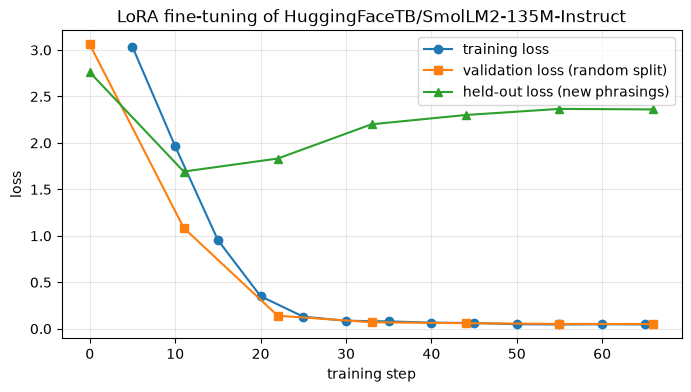

,step,epoch,validation loss,validation token acc,new-phrasing loss,new-phrasing token acc
0,0,0.0,3.059,0.416,2.760,0.425
1,11,0.5,1.086,0.746,1.692,0.613
2,22,1.0,0.140,0.963,1.832,0.670
3,33,1.5,0.070,0.975,2.201,0.613
4,44,2.0,0.060,0.974,2.300,0.613
5,55,2.5,0.052,0.979,2.366,0.613
6,66,3.0,0.051,0.978,2.361,0.613


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
val_log = history.dropna(subset=["eval_validation_loss"])
new_log = history.dropna(subset=["eval_new_phrasings_loss"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(train_log["step"], train_log["loss"], marker="o", label="training loss")
ax.plot(val_log["step"], val_log["eval_validation_loss"], marker="s", label="validation loss (random split)")
ax.plot(new_log["step"], new_log["eval_new_phrasings_loss"], marker="^", label="held-out loss (new phrasings)")
ax.set_xlabel("training step")
ax.set_ylabel("loss")
ax.set_title(f"LoRA fine-tuning of {BASE_MODEL_ID}")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Each evaluation set is logged as its own row; token accuracy = share of reply tokens predicted exactly
summary = val_log[["step", "epoch", "eval_validation_loss", "eval_mean_token_accuracy"]].merge(
    new_log[["step", "eval_new_phrasings_loss", "eval_mean_token_accuracy"]], on="step")
summary.columns = ["step", "epoch", "validation loss", "validation token acc", "new-phrasing loss", "new-phrasing token acc"]
summary.round(3)

### Understanding Fine-Tuning Metrics

Read the three curves together:

- **Training loss**: the model's error on the batches it learns from. It should go down.
- **Validation loss (random split)**: the error on the 20% of examples we held back. Here every one of them repeats a training question and a training answer (44/44, measured in section 2), so this curve mostly tracks memorization and follows the training loss down.
- **Held-out loss (new phrasings)**: the error on questions worded differently from every training template, with reference answers in our own words. This is the closest thing we have to real customer traffic.

The table adds **token accuracy**, the share of reply tokens the model predicts exactly.

#### What to Look For
✅ **Good Signs**
- Training and validation loss falling together

- Held-out loss falling as well, or at least not rising

⚠️ **Warning Signs**
- Validation loss increasing while training loss decreases

- Large gaps between training and validation metrics

- Erratic or unstable curves

#### What this run shows
Training took about 2 minutes on this Mac's GPU (Apple M4, MPS); the same notebook with `DEVICE = "cpu"` trained in 6 minutes. Validation loss fell from 3.06 before training to 0.05, and token accuracy rose from 0.42 to 0.98: the model reproduces the training answers almost word for word. By the random split alone, this run looks perfect.

The held-out curve tells a different story. It fell from 2.76 to 1.69 in the first half epoch, then climbed back to 2.36 while the validation loss kept falling. That is the overfitting signature from the list above, and the random split could not show it, because its examples are copies of the training data.

Treat the held-out curve as a warning rather than a verdict. Its reference answers use our own wording, so part of the rise is the model committing to the training templates' style. Stopping at its minimum is not automatically better either: in a separate run with 2 epochs instead of 3, the held-out loss ended lower (2.04) but the fact check in section 7 got worse (2 of 7 facts on new phrasings instead of 4). Loss measures how well the model predicts text, not whether its answers are right, which is why section 7 checks the facts directly. The real cure for this curve is more varied training data.

In [12]:
ADAPTER_DIR = DATA_DIR / "banking-lora-adapter"
trainer.save_model(str(ADAPTER_DIR))

adapter_mb = (ADAPTER_DIR / "adapter_model.safetensors").stat().st_size / 1e6
print(f"Saved to {ADAPTER_DIR.name}/: {sorted(f.name for f in ADAPTER_DIR.iterdir())}")
print(f"Adapter weights: {adapter_mb:.1f} MB. The base model weights are not copied; they are loaded from {BASE_MODEL_ID}.")

Saved to banking-lora-adapter/: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
Adapter weights: 19.6 MB. The base model weights are not copied; they are loaded from HuggingFaceTB/SmolLM2-135M-Instruct.


## 6. Integrating the Fine-Tuned Model into an Agent

A 135M-parameter model cannot reliably decide when to call a tool or produce well-formed tool calls, so we do not hand it the agent loop. Instead we use a common production pattern:

- A **router** decides what kind of request it is.
- **Account actions** (transfers, lookups) go to deterministic tools, never to generated text.
- **Product questions** go to the fine-tuned model, wrapped behind a plain function.
- **Anything else** is handed off, because the specialist only knows what it was trained on.

The router here is a few keyword rules so the notebook runs without an API key. In production that step is usually a larger LLM with tool calling or a trained intent classifier, while the small fine-tuned model stays the cheap, fast specialist.

First, load the model the way a serving process would: base weights plus the saved adapter from disk, merged into one plain model.

In [13]:
from peft import AutoPeftModelForCausalLM

expert_model = AutoPeftModelForCausalLM.from_pretrained(str(ADAPTER_DIR), dtype=torch.float32)
expert_model = expert_model.merge_and_unload().to(DEVICE)  # fold the LoRA weights into the base weights

def banking_expert(question: str) -> str:
    # The fine-tuned model behind a function the agent can call
    return ask(expert_model, question)

print(banking_expert("What savings accounts do you offer?"))

Here's what you need to know about savings: We offer three types of savings accounts: Basic (no minimum balance), Premium ($2,500 minimum, no fees), and Student (no fees with valid student ID).


In [14]:
import re
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# Tools: deterministic code that a real system would back with authenticated APIs
def account_lookup(account_id: str) -> str:
    # Look up account information by account ID (requires authentication)
    return f"Account {account_id} information is available after authentication."

def transfer_payment(destination_account: str, amount: float) -> str:
    # Prepare a transfer; the customer still has to authenticate to confirm it
    return f"Transfer of ${amount:,.2f} to account {destination_account} is prepared. Please authenticate to confirm it."

# What the fine-tuned model was trained on. Questions outside these topics are handed off.
KB_TOPICS = ("checking", "savings", "business", "account type", "apy", "interest", "minimum balance", "student")

class AgentState(TypedDict):
    query: str
    route: str
    answer: str

def route_query(state: AgentState) -> dict:
    q = state["query"].lower()
    account = re.search(r"\b\d{6,}\b", q)
    if re.search(r"\b(transfer|send|wire|pay)\b", q) and re.search(r"\$\s?\d", q) and account:
        route = "transfer"
    elif account or re.search(r"\bmy (balance|account)\b", q):
        route = "lookup"
    elif any(topic in q for topic in KB_TOPICS):
        route = "knowledge"
    else:
        route = "handoff"
    return {"route": route}

def transfer_node(state: AgentState) -> dict:
    amount = float(re.search(r"\$\s?([\d,]+(?:\.\d+)?)", state["query"]).group(1).replace(",", ""))
    account = re.search(r"\b\d{6,}\b", state["query"]).group(0)
    return {"answer": transfer_payment(account, amount)}

def lookup_node(state: AgentState) -> dict:
    account = re.search(r"\b\d{6,}\b", state["query"])
    return {"answer": account_lookup(account.group(0) if account else "on file")}

def knowledge_node(state: AgentState) -> dict:
    return {"answer": banking_expert(state["query"])}

def handoff_node(state: AgentState) -> dict:
    return {"answer": "I can answer questions about our checking, savings and business accounts. "
                      "For anything else, I'll connect you with a member of our support team."}

builder = StateGraph(AgentState)
builder.add_node("router", route_query)
builder.add_node("transfer", transfer_node)
builder.add_node("lookup", lookup_node)
builder.add_node("knowledge", knowledge_node)
builder.add_node("handoff", handoff_node)
builder.add_edge(START, "router")
builder.add_conditional_edges("router", lambda state: state["route"], ["transfer", "lookup", "knowledge", "handoff"])
for node in ["transfer", "lookup", "knowledge", "handoff"]:
    builder.add_edge(node, END)
agent = builder.compile()

test_queries = [
    "What account types do you offer?",
    "Is there a checking account for students?",
    "What are the fees for wire transfers?",
    "I need information about overdraft protection",
    "I want to transfer $50,000 to account 1234567",
    "What's the balance on account 98765432?",
]

for query in test_queries:
    result = agent.invoke({"query": query})
    print(f"Query: {query}\nRoute: {result['route']}\nResponse: {result['answer']}\n")

Query: What account types do you offer?
Route: knowledge
Response: I'll explain about our account types. We offer three types of accounts: Basic (no minimum balance), Premium ($2,500 minimum, no fees), and Student (no fees with valid student ID). This information about accounts is current as of today. Please check our website for any updates.



Query: Is there a checking account for students?
Route: knowledge
Response: We offer three types of checking accounts: Basic (no minimum balance), Premium ($2,500 minimum, no fees), and Student (no fees with valid student ID). Is there anything specific you'd like to know more about?

Query: What are the fees for wire transfers?
Route: handoff
Response: I can answer questions about our checking, savings and business accounts. For anything else, I'll connect you with a member of our support team.

Query: I need information about overdraft protection
Route: handoff
Response: I can answer questions about our checking, savings and business accounts. For anything else, I'll connect you with a member of our support team.

Query: I want to transfer $50,000 to account 1234567
Route: transfer
Response: Transfer of $50,000.00 to account 1234567 is prepared. Please authenticate to confirm it.

Query: What's the balance on account 98765432?
Route: lookup
Response: Account 98765432 information is a

The routing does its job: the transfer and the balance lookup never touch generated text, and the two questions outside the knowledge base (wire fees, overdraft protection) are handed off instead of answered.

The knowledge answers show the specialist's limits. "What account types do you offer?" gets only the checking paragraph, and the merged model's answer to "What savings accounts do you offer?" a few cells above is the checking paragraph relabeled as savings. A router cannot fix that; it can only keep the specialist on the questions it was trained for. Section 7 measures how often it happens.

*Tip: if you later need several specialised models, train one LoRA adapter per specialty on the same base model. PEFT can load several adapters into one model (`load_adapter`) and switch between them (`set_adapter`), so each LangGraph node can use its own specialist while sharing a single copy of the base weights.*

## 7. Base Model vs Fine-Tuned Model: What This Run Shows

Instead of hand-picked examples, we run every question in the test set through three setups and measure two simple things: how many of the expected knowledge-base facts (such as "$2,500" or "1.5% APY") appear in each answer, and whether the answer quotes facts that belong to a different product than the one asked about (for example, savings rates in an answer about checking).

1. **Base model**: the original model with the same system message, no extra information.
2. **Base model + facts in the prompt**: the original model with the knowledge base pasted into its system message. This is what prompt engineering or retrieval (RAG) would give you without any training, so it is the baseline fine-tuning has to beat.
3. **Fine-tuned model**: the LoRA-tuned model with the plain system message.

The base runs use the same model object with the LoRA adapter switched off (`disable_adapter()`), so the only difference between setups 1 and 3 is the adapter. Both checks are deliberately simple string matches: they cannot tell whether an answer is focused, polite or free of invented details, so read the answers too.

In [15]:
peft_model = trainer.model
kb_text = " ".join(f"{topic.capitalize()}: {details}" for topic, details in kb_docs[0]["content"].items())
KB_PROMPT = f"{SYSTEM_PROMPT} Answer using only these facts. {kb_text}"

# The distinctive facts of each product in the knowledge base
product_facts = {
    "checking": ["$2,500", "student ID"],
    "savings": ["0.5% APY", "1.5% APY", "$10,000"],
    "business": ["unlimited transactions", "merchant services", "Standard and Premium"],
}

def facts_found(answer, facts):
    normalize = lambda s: s.lower().replace(",", "")
    return sum(normalize(fact) in normalize(answer) for fact in facts)

def other_product_facts(answer, product):
    # Facts that belong to a different product than the one the customer asked about
    return [f for p, facts in product_facts.items() if p != product for f in facts if facts_found(answer, [f])]

setups = ["base", "base + facts in prompt", "fine-tuned"]
rows = []
for item in test_set:
    with peft_model.disable_adapter():  # the original model, without the LoRA adapter
        answers = {"base": ask(peft_model, item["question"]),
                   "base + facts in prompt": ask(peft_model, item["question"], system=KB_PROMPT)}
    answers["fine-tuned"] = ask(peft_model, item["question"])
    for setup, answer in answers.items():
        rows.append({"question": item["question"], "phrasing": item["phrasing"], "setup": setup, "answer": answer,
                     "found": facts_found(answer, item["facts"]), "expected": len(item["facts"]),
                     "mixed_up": other_product_facts(answer, item["product"])})
results = pd.DataFrame(rows)

summary = []
for setup in setups:
    r = results[results["setup"] == setup]
    new, seen = r[r["phrasing"] == "new"], r[r["phrasing"] == "seen"]
    summary.append({
        "setup": setup,
        "KB facts found, new phrasings (6 questions)": f"{new['found'].sum()}/{new['expected'].sum()}",
        "KB facts found, seen phrasings (2 questions)": f"{seen['found'].sum()}/{seen['expected'].sum()}",
        "answers quoting another product's facts": f"{(r['mixed_up'].str.len() > 0).sum()}/{len(r)}",
    })
pd.DataFrame(summary).set_index("setup")

,"KB facts found, new phrasings (6 questions)","KB facts found, seen phrasings (2 questions)",answers quoting another product's facts
setup,,,
base,0/7,0/5,0/8
base + facts in prompt,4/7,0/5,3/8
fine-tuned,4/7,5/5,2/8


In [16]:
for question, group in results.groupby("question", sort=False):
    print(f"Q ({group['phrasing'].iloc[0]} phrasing): {question}")
    for _, r in group.iterrows():
        note = f", quotes other products: {r['mixed_up']}" if r["mixed_up"] else ""
        print(f"  [{r['setup']}: {r['found']}/{r['expected']} facts{note}] {r['answer']}")
    print()

Q (new phrasing): What is the minimum balance for a Premium checking account?
  [base: 0/1 facts] The minimum balance for a Premium checking account is typically $1,000. However, this can vary depending on the type of account and the specific requirements of your account. It's always best to check with your bank or credit card company for the most accurate and up-to-date information.
  [base + facts in prompt: 1/1 facts] The minimum balance for a Premium checking account is $2,500.
  [fine-tuned: 0/1 facts, quotes other products: ['0.5% APY', '1.5% APY', '$10,000']] Our Premium checking accounts include Regular (0.5% APY), High-Yield (1.5% APY with $10,000 minimum), and Goal-Based savings with customizable targets. Is there anything specific you'd like to know more about?

Q (new phrasing): I'm a student. Is there a checking account without fees?
  [base: 0/1 facts] As a banking assistant, I specialize in providing financial assistance to students. While there are no direct fees associ

### Questions outside the training data

A fine-tuned model does not learn where its knowledge ends. Two questions from the original version of this tutorial cover topics that are not in the knowledge base at all:

In [17]:
all_kb_facts = [fact for facts in product_facts.values() for fact in facts]
for question in ["What are the fees for wire transfers?", "I need information about overdraft protection"]:
    with peft_model.disable_adapter():
        base_answer = ask(peft_model, question)
    tuned_answer = ask(peft_model, question)
    leaked = [fact for fact in all_kb_facts if facts_found(tuned_answer, [fact])]
    print(f"Q: {question}")
    print(f"  [base] {base_answer}")
    print(f"  [fine-tuned] {tuned_answer}")
    print(f"  Unrelated KB facts in the fine-tuned answer: {leaked or 'none'}\n")

Q: What are the fees for wire transfers?
  [base] The fees for wire transfers vary depending on the type of wire transfer, the amount, and the method used. Here are some general guidelines:

For wire transfers over $100, the fees are typically 1% to 2% of the amount, depending on the method and the type of wire transfer.

For wire transfers over $500, the fees are typically 1% to 2% of the amount, depending on the method and the type of wire
  [fine-tuned] We offer three types of wire transfers: Basic (no minimum balance), Premium ($2,500 minimum, no fees) and Student (no fees with valid student ID). This information about wire transfers is current as of today. Please check our website for any updates.
  Unrelated KB facts in the fine-tuned answer: ['$2,500', 'student ID']



Q: I need information about overdraft protection
  [base] Hello, I'm here to help you with your banking needs. I'm a banking assistant with expertise in providing accurate, compliant information.

What's your banking situation? Do you have an account with a bank that's currently experiencing an overdraft, or are you looking for help with a specific issue?
  [fine-tuned] We offer three types of overdraft protection services: Basic (no minimum balance), Premium ($2,500 minimum, no fees), and Student (no fees with valid student ID). This information about overdraft protection is current as of today. Please check our website for any updates.
  Unrelated KB facts in the fine-tuned answer: ['$2,500', 'student ID']



### What the numbers say

- **The base model knows nothing about this bank** (0 of 12 facts) and invents specifics with confidence: a "$1,000" Premium minimum, "100 transactions per month" for business accounts, wire fees of "1% to 2%".
- **Fine-tuning taught the training answers, word for word.** On the two phrasings it was trained on, the fine-tuned model returned every fact (5/5). Pasting the facts into the base model's prompt got 0/5 on the same questions: a 135M model is poor at using its context.
- **On new phrasings, fine-tuning only tied the prompt baseline (4/7 each), and both mixed up products.** The fine-tuned model behaves like a lookup of memorized paragraphs keyed on words in the question: asked about Premium checking, it recited the savings paragraph; asked about High-Yield savings, it recited the checking paragraph. The prompt baseline quoted another product's facts in 3 of 8 answers, the fine-tuned model in 2 of 8.
- **Outside the knowledge base, fine-tuning made answers worse in a risky way.** The base model gives a generic answer about wire fees (with invented percentages) and asks a clarifying question about overdraft protection. The fine-tuned model announces "three types of wire transfers" and "three types of overdraft protection" by filling in the checking template, in the bank's own voice. Nothing in the training data showed it how to say "I don't have that information".

**Takeaway:**

With 216 template-generated examples of three facts, a tiny model learns the templates, not the knowledge. That is not a failure of the technique; it is exactly what this data teaches. To get real gains, train on diverse, realistic phrasings and include examples where the right answer is a refusal or a handoff, use a larger base model, and keep exact facts that change over time in retrieval or the prompt, using fine-tuning for style, format and behavior. Whatever you do, compare against the "facts in the prompt" baseline on held-out phrasings before deciding that fine-tuning paid off.

For reference, a separate run on the same Mac with `BASE_MODEL_ID = "HuggingFaceTB/SmolLM2-360M-Instruct"` (same data and settings) found 6 of 7 facts on new phrasings with no product mix-ups, but it still invented a rate ("High-Yield (1.75% APY)") in one answer and still answered both out-of-scope questions with made-up offers. A bigger model generalizes better; it does not fix the data.

## 8. Best Practices for Fine-Tuning

| Topic                   | Recommendation                                                                                   |
|-------------------------|--------------------------------------------------------------------------------------------------|
| **Train/Validation Split** | Always reserve at least 10% of your data for validation, and make sure some of it is worded differently from anything in training. A random split of templated data repeats the training questions and answers, so it measures memorization, not generalization. |
| **Data Diversity**         | Many phrasings of the same few facts teach the model those phrasings. Cover each behavior with genuinely different questions, answers and contexts, ideally drawn from real user queries, and include questions the assistant should decline or hand off. Otherwise it answers everything in the trained voice (section 7). |
| **Early Stopping**         | Not on by default in TRL. Evaluate during training, add `EarlyStoppingCallback` with `load_best_model_at_end=True`, and pick the checkpoint by the loss on a set of held-out phrasings (kept separate from your final test set), not on a split that repeats the training data. |
| **Example Truncation**     | `SFTConfig(max_length=...)` truncates longer examples. Check your token lengths first (ours are under 100 tokens) and keep messages concise and relevant. |
| **Evaluation Metrics**     | TRL logs loss and token-level accuracy. They say how well the model reproduces reference text, not whether answers are correct, so also run a task check on your own test set, such as the fact check in section 7 or exact-match metrics. |
| **Knowledge vs Behavior**  | Fine-tuning is best at teaching style, format and behavior. For facts that change or must be exact, keep them in a retrieval step or the prompt, and compare against that baseline before you train. |

## 9. Next Steps

- Scale Up the Base Model:
  Change `BASE_MODEL_ID` to a larger instruct model (for example a 0.5B to 3B model on a GPU). The data, training and evaluation code stay the same. Even the 360M model avoided the product mix-ups seen here (section 7), but it still invented details, so pair a bigger model with better data.

- Diversify the Training Data:
  Add more knowledge-base documents (the commented-out ones in section 2 are a start), real customer phrasings, and examples where the right answer is "I don't have that information".

- Automate Data Refresh:
  Schedule regular (e.g., nightly) re-training with new domain data to keep the model up-to-date with evolving knowledge and requirements.

- Add Compliance & Audit Nodes:
  Integrate additional LangGraph nodes (potentially with their own fine-tuned adapters) to automatically check responses for compliance and flag sensitive topics.

- Monitor agent performance and costs with tools like LangSmith, and continuously evaluate real user queries to iterate and improve your training data and workflow.

---
📖 **Want the decisions behind agents like this one, explained without code?** [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=tutorials--fine-tunning-agents--fine-tuning-agents-guide&click=book-nb-agents&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2&retarget=0&text=book-nb-agents) by the author of this repository covers this and much more. Available on Amazon.